# Proximity Prestige en una red de amigos de Facebook

**Idea:** la amistad en Facebook es no dirigida, pero el prestigio se define en redes **dirigidas**. Por eso la red se construye con las *interacciones*: hay una arista $i \rightarrow j$ si el amigo $i$ le da likes, comenta o etiqueta al amigo $j$ (según las métricas de redes sociales vistas en clase).

- $G = (N, A)$, con $n$ nodos (amigos) y $m$ aristas (interacciones).
- $Influence(i)$: conjunto de nodos que pueden llegar a $i$ con un camino dirigido.
- $AvDist(i) = \frac{\sum_{j \in Influence(i)} Dist(j, i)}{|Influence(i)|}$
- $InfluenceFraction(i) = \frac{|Influence(i)|}{n - 1}$
- $P_P(i) = \frac{InfluenceFraction(i)}{AvDist(i)}$

# Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from collections import deque

# Read data

El archivo contiene una fila por interacción: quién interactúa (`source`), con quién (`target`) y cuántos likes, comentarios y etiquetas. **Los nombres del ejemplo son ficticios**; para usar tus amigos reales solo se reemplaza `datasets/facebook_amigos.csv` con el mismo formato.

In [2]:
df = pd.read_csv('datasets/facebook_amigos.csv')
df.head()

  source target  likes  comments  tags
0    Ana  Carla     13         6     3
1   Beto  Elena     12         2     1
2  Carla   Iris     25         4     1
3  Carla    Ana     12         3     2
4  Diego    Gus     24         7     2

# Show info

In [3]:
df.info()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   source    20 non-null     str  
 1   target    20 non-null     str  
 2   likes     20 non-null     int64
 3   comments  20 non-null     int64
 4   tags      20 non-null     int64
dtypes: int64(3), str(2)
memory usage: 932.0 bytes
           likes   comments       tags
count  20.000000  20.000000  20.000000
mean   17.450000   4.500000   1.400000
std     7.542686   3.017493   1.187656
min     5.000000   0.000000   0.000000
25%    11.750000   2.000000   0.000000
50%    18.500000   4.500000   1.000000
75%    24.000000   7.000000   2.250000
max    28.000000   9.000000   3.000000


# Define the edges (interaction threshold)

Se decide cuándo una interacción cuenta como arista. Se asigna un puntaje (comentar y etiquetar pesan más que un like) y se conservan las interacciones con puntaje mínimo.

In [4]:
df['score'] = df['likes'] + 3 * df['comments'] + 5 * df['tags']
threshold = 15
edges = df[df['score'] >= threshold]
print('Interacciones totales:', len(df))
print('Aristas conservadas:', len(edges))

Interacciones totales: 20
Aristas conservadas: 18


# Build the directed graph G = (N, A)

In [5]:
nodes = sorted(set(df['source']) | set(df['target']))
n = len(nodes)
A = {u: set() for u in nodes}        # lista de adyacencia: u -> {v}
for _, r in edges.iterrows():
    A[r['source']].add(r['target'])
m = sum(len(v) for v in A.values())
print('n =', n, ' m =', m)

n = 16  m = 18


# Degree prestige and gregariousness

In [6]:
in_degree = {u: 0 for u in nodes}
out_degree = {u: len(A[u]) for u in nodes}
for u in nodes:
    for v in A[u]:
        in_degree[v] += 1

degree_prestige = {u: in_degree[u] / (n - 1) for u in nodes}   # P_D(i) = InDegree / (n-1)
gregariousness = {u: out_degree[u] / (n - 1) for u in nodes}   # G_D(i) = OutDegree / (n-1)
pd.DataFrame({'P_D': degree_prestige, 'G_D': gregariousness}).sort_values('P_D', ascending=False).head()

            P_D       G_D
Ana    0.200000  0.066667
Carla  0.200000  0.133333
Elena  0.200000  0.066667
Gus    0.133333  0.066667
Iris   0.133333  0.066667

# Shortest distances (BFS)

Para saber quién llega a quién, se invierte el grafo: caminar sobre la red invertida desde $i$ equivale a recorrer todos los $j$ que alcanzan a $i$, y la distancia BFS es $Dist(j, i)$.

In [7]:
def reverse_graph(A):
    R = {u: set() for u in A}
    for u in A:
        for v in A[u]:
            R[v].add(u)
    return R

def bfs_distances(R, i):
    # Dist(j, i) para todo j que puede alcanzar a i
    dist = {i: 0}
    queue = deque([i])
    while queue:
        u = queue.popleft()
        for w in R[u]:
            if w not in dist:
                dist[w] = dist[u] + 1
                queue.append(w)
    del dist[i]
    return dist

R = reverse_graph(A)
bfs_distances(R, nodes[0])

{'Carla': 1, 'Karla': 1, 'Gus': 1, 'Iris': 2, 'Fer': 2, 'Diego': 2, 'Elena': 2, 'Jorge': 3, 'Mar': 3, 'Luis': 3, 'Nico': 3, 'Olga': 3, 'Beto': 3, 'Hugo': 4}

# Proximity prestige from scratch

In [8]:
def proximity_prestige(A):
    nodes = list(A.keys())
    n = len(nodes)
    R = reverse_graph(A)
    result = {}
    for i in nodes:
        dist = bfs_distances(R, i)
        influence = len(dist)                       # |Influence(i)|
        if influence == 0:
            result[i] = {'influence': 0, 'avdist': np.nan, 'fraction': 0.0, 'P_P': 0.0}
            continue
        avdist = sum(dist.values()) / influence     # AvDist(i)
        fraction = influence / (n - 1)              # InfluenceFraction(i)
        result[i] = {'influence': influence, 'avdist': avdist,
                     'fraction': fraction, 'P_P': fraction / avdist}
    return pd.DataFrame(result).T

pp = proximity_prestige(A)
pp['P_D'] = pd.Series(degree_prestige)
pp = pp.sort_values('P_P', ascending=False)
pp

       influence    avdist  fraction       P_P       P_D
Ana         14.0  2.357143  0.933333  0.395960  0.200000
Carla       14.0  2.571429  0.933333  0.362963  0.200000
Iris        14.0  3.214286  0.933333  0.290370  0.133333
Gus          7.0  1.857143  0.466667  0.251282  0.133333
Elena        4.0  1.250000  0.266667  0.213333  0.200000
Diego        2.0  1.500000  0.133333  0.088889  0.066667
Jorge        1.0  1.000000  0.066667  0.066667  0.066667
Fer          1.0  1.000000  0.066667  0.066667  0.066667
Luis         1.0  1.000000  0.066667  0.066667  0.066667
Nico         1.0  1.000000  0.066667  0.066667  0.066667
Hugo         0.0       NaN  0.000000  0.000000  0.000000
Beto         0.0       NaN  0.000000  0.000000  0.000000
Karla        0.0       NaN  0.000000  0.000000  0.000000
Mar          0.0       NaN  0.000000  0.000000  0.000000
Olga         0.0       NaN  0.000000  0.000000  0.000000
Paco         0.0       NaN  0.000000  0.000000  0.000000

# Validation with networkx

In [9]:
G = nx.DiGraph()
G.add_nodes_from(nodes)
for u in A:
    for v in A[u]:
        G.add_edge(u, v)

check = {}
for i in nodes:
    d = nx.single_source_shortest_path_length(G.reverse(), i)
    d.pop(i)
    check[i] = (len(d) / (n - 1)) / (sum(d.values()) / len(d)) if d else 0.0
check = pd.Series(check)
print('Máxima diferencia contra networkx:', np.abs(check - pp['P_P']).max())

Máxima diferencia contra networkx: 0.0


# Ranking plotting

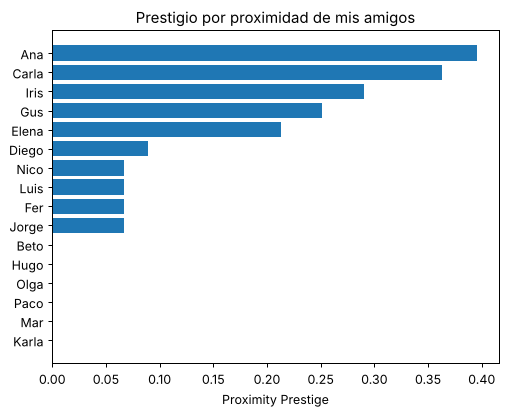

In [10]:
top = pp.sort_values('P_P')
plt.barh(top.index, top['P_P'], color='tab:blue')
plt.xlabel('Proximity Prestige')
plt.title('Prestigio por proximidad de mis amigos')
plt.show()

# Network plotting

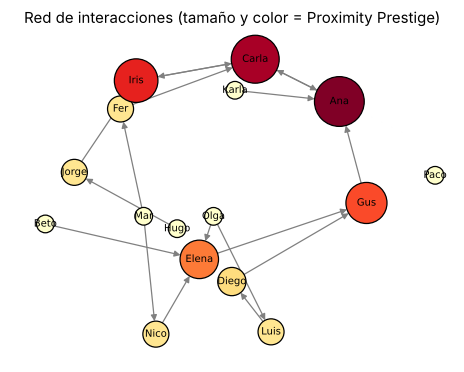

In [11]:
pos = nx.spring_layout(G, seed=3, k=0.9)
sizes = [200 + 3500 * pp.loc[u, 'P_P'] for u in G.nodes]
colors = [pp.loc[u, 'P_P'] for u in G.nodes]
nx.draw_networkx(G, pos, node_size=sizes, node_color=colors, cmap='YlOrRd',
                 edgecolors='k', arrows=True, arrowsize=10, font_size=8, edge_color='gray')
plt.title('Red de interacciones (tamaño y color = Proximity Prestige)')
plt.axis('off')
plt.show()

# Degree prestige vs proximity prestige

In [12]:
comp = pp[['P_D', 'P_P']].copy()
comp['rank_PD'] = comp['P_D'].rank(ascending=False)
comp['rank_PP'] = comp['P_P'].rank(ascending=False)
print(comp.sort_values('rank_PP'))
print('Correlación de Spearman:', comp['P_D'].corr(comp['P_P'], method='spearman'))

            P_D       P_P  rank_PD  rank_PP
Ana    0.200000  0.395960      2.0      1.0
Carla  0.200000  0.362963      2.0      2.0
Iris   0.133333  0.290370      4.5      3.0
Gus    0.133333  0.251282      4.5      4.0
Elena  0.200000  0.213333      2.0      5.0
Diego  0.066667  0.088889      8.0      6.0
Jorge  0.066667  0.066667      8.0      8.5
Fer    0.066667  0.066667      8.0      8.5
Luis   0.066667  0.066667      8.0      8.5
Nico   0.066667  0.066667      8.0      8.5
Hugo   0.000000  0.000000     13.5     13.5
Beto   0.000000  0.000000     13.5     13.5
Karla  0.000000  0.000000     13.5     13.5
Mar    0.000000  0.000000     13.5     13.5
Olga   0.000000  0.000000     13.5     13.5
Paco   0.000000  0.000000     13.5     13.5
Correlación de Spearman: 0.9721809966625455


# Effect of the threshold

In [13]:
rows = []
for t in [1, 10, 15, 20, 30, 40]:
    e = df[df['score'] >= t]
    At = {u: set() for u in nodes}
    for _, r in e.iterrows():
        At[r['source']].add(r['target'])
    p = proximity_prestige(At)['P_P']
    rows.append({'threshold': t, 'aristas': len(e), 'top 1': p.idxmax(), 'P_P top 1': round(p.max(), 3)})
pd.DataFrame(rows)

   threshold  aristas  top 1  P_P top 1
0          1       20    Ana      0.405
1         10       20    Ana      0.405
2         15       18    Ana      0.396
3         20       17    Ana      0.376
4         30       12  Carla      0.240
5         40       10  Carla      0.208

## Conclusión

Este programa implementó el algoritmo de Proximity Prestige sobre una red de amigos de Facebook modelada como grafo dirigido, donde una arista representa que un amigo interactúa (likes, comentarios, etiquetas) con otro. A diferencia del degree prestige, que solo cuenta cuántas interacciones recibe un nodo, el proximity prestige considera el conjunto de influencia completo: cuántos amigos pueden llegar al nodo mediante un camino dirigido y qué tan cerca están, penalizando con la fracción de influencia a quienes son alcanzados por pocos.

Los resultados se validaron contra `networkx` con diferencia nula y se compararon con el degree prestige: los amigos más populares ocupan los primeros lugares en ambas medidas, pero el proximity prestige puede reordenar a quienes reciben pocas interacciones directas y aun así son alcanzables por gran parte de la red. También se observó que el umbral que define qué interacción cuenta como arista cambia el ranking, por lo que esa decisión de diseño debe justificarse al aplicar el algoritmo a datos reales.